In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv('/content/Placement_Analytics_Dataset.csv')

In [4]:
df.head()

,Student_ID,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Placement_Status,Offer_Count,Salary,Department,Skill_Profile
0,STU00001,77.96,67.36,78.77,0.0,NaN,89.07,Placed,2,5.98,ECE,Web Development
1,STU00002,65.70,58.65,57.04,1.0,0.0,38.22,Placed,1,5.68,CSE,Data Science
2,STU00003,89.59,68.14,71.35,1.0,1.0,54.86,Placed,4,8.79,ECE,Software Development
3,STU00004,64.37,51.66,65.90,2.0,0.0,63.03,Not Placed,0,0.00,EEE,Web Development
4,STU00005,71.93,48.43,70.07,0.0,0.0,79.05,Placed,1,4.79,IT,Web Development


In [5]:
df.shape

(3503, 12)

In [6]:
df.columns

Index(['Student_ID', 'Academic_Performance', 'Coding_Score', 'Project_Score',
       'Certifications', 'Internships', 'Communication_Score',
       'Placement_Status', 'Offer_Count', 'Salary', 'Department',
       'Skill_Profile'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3503 entries, 0 to 3502
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            3503 non-null   object 
 1   Academic_Performance  3474 non-null   float64
 2   Coding_Score          3475 non-null   float64
 3   Project_Score         3482 non-null   float64
 4   Certifications        3489 non-null   float64
 5   Internships           3489 non-null   float64
 6   Communication_Score   3482 non-null   float64
 7   Placement_Status      3503 non-null   object 
 8   Offer_Count           3503 non-null   int64  
 9   Salary                3503 non-null   float64
 10  Department            3503 non-null   object 
 11  Skill_Profile         3503 non-null   object 
dtypes: float64(7), int64(1), object(4)
memory usage: 328.5+ KB


In [8]:
df.describe()

,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Offer_Count,Salary
count,3474.000000,3475.000000,3482.000000,3489.000000,3489.000000,3482.000000,3503.000000,3503.000000
mean,72.183569,68.454242,70.185689,1.774721,1.152766,70.343277,1.631173,5.840859
std,11.821057,14.866320,12.847260,1.304866,1.056812,12.038604,1.284209,3.506441
min,45.000000,30.000000,35.000000,0.000000,0.000000,35.000000,0.000000,0.000000
25%,64.070000,58.475000,61.372500,1.000000,0.000000,62.167500,1.000000,4.095000
50%,72.330000,68.780000,70.195000,2.000000,1.000000,70.350000,1.000000,6.670000
75%,80.335000,78.945000,79.057500,3.000000,2.000000,78.520000,2.000000,8.340000
max,98.000000,100.000000,100.000000,6.000000,4.000000,100.000000,5.000000,14.030000


In [9]:
df.isnull().sum()

,0
Student_ID,0
Academic_Performance,29
Coding_Score,28
Project_Score,21
Certifications,14
Internships,14
Communication_Score,21
Placement_Status,0
Offer_Count,0
Salary,0


In [10]:
df.duplicated().sum()

np.int64(3)

In [11]:
df = df.drop_duplicates()

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.isnull().sum()

,0
Student_ID,0
Academic_Performance,28
Coding_Score,28
Project_Score,21
Certifications,14
Internships,14
Communication_Score,21
Placement_Status,0
Offer_Count,0
Salary,0


In [14]:
numeric_columns = [
    'Academic_Performance',
    'Coding_Score',
    'Project_Score',
    'Certifications',
    'Internships',
    'Communication_Score'
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [15]:
df.isnull().sum()

,0
Student_ID,0
Academic_Performance,0
Coding_Score,0
Project_Score,0
Certifications,0
Internships,0
Communication_Score,0
Placement_Status,0
Offer_Count,0
Salary,0


In [16]:
df['Placement_Status'].value_counts()

,count
Placement_Status,
Placed,2758
Not Placed,742


In [17]:
df.groupby('Placement_Status')[
    ['Academic_Performance',
     'Coding_Score',
     'Project_Score',
     'Certifications',
     'Internships',
     'Communication_Score']
].mean()

,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score
Placement_Status,,,,,,
Not Placed,68.857561,61.176590,66.237615,1.416442,0.870620,67.931698
Placed,73.082005,70.429025,71.252117,1.872734,1.228789,70.990529


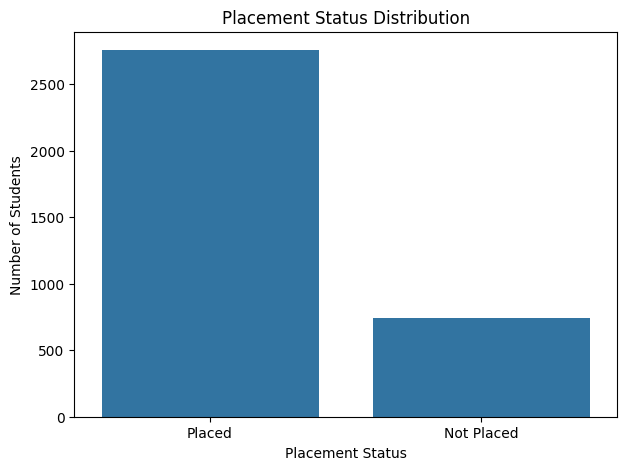

In [18]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Placement_Status'
)

plt.title('Placement Status Distribution')
plt.xlabel('Placement Status')
plt.ylabel('Number of Students')

plt.show()

In [19]:
placed_df = df[df['Placement_Status'] == 'Placed']

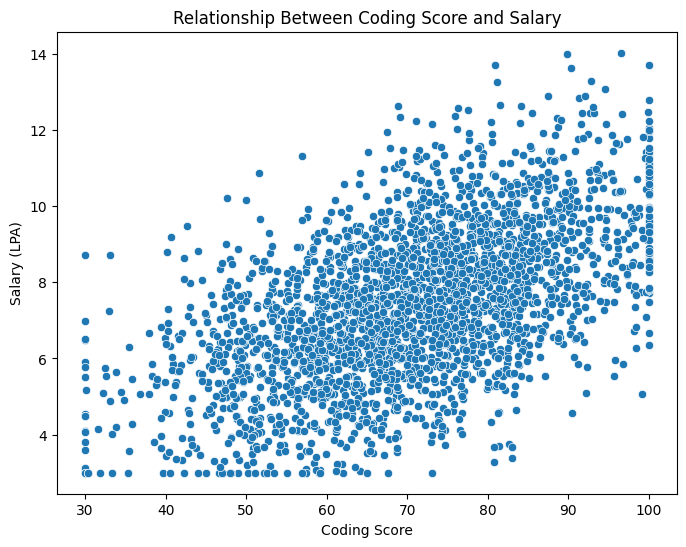

In [20]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=placed_df,
    x='Coding_Score',
    y='Salary'
)

plt.title('Relationship Between Coding Score and Salary')
plt.xlabel('Coding Score')
plt.ylabel('Salary (LPA)')

plt.show()

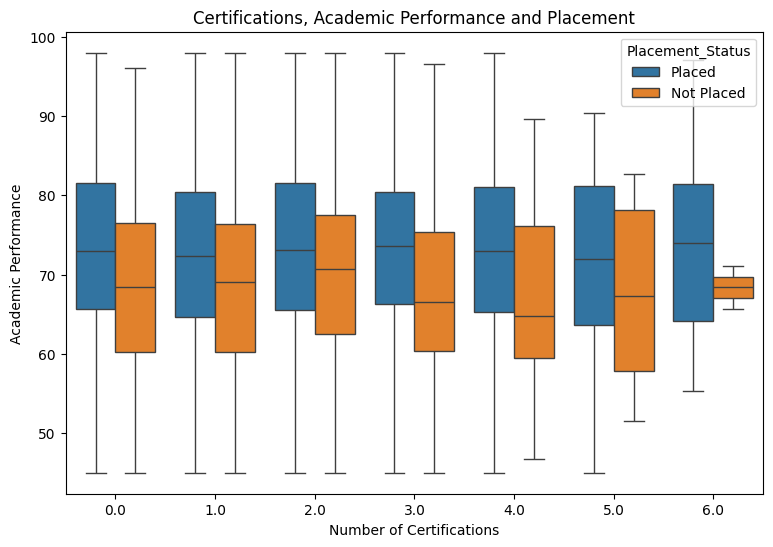

In [21]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='Certifications',
    y='Academic_Performance',
    hue='Placement_Status'
)

plt.title('Certifications, Academic Performance and Placement')
plt.xlabel('Number of Certifications')
plt.ylabel('Academic Performance')

plt.show()

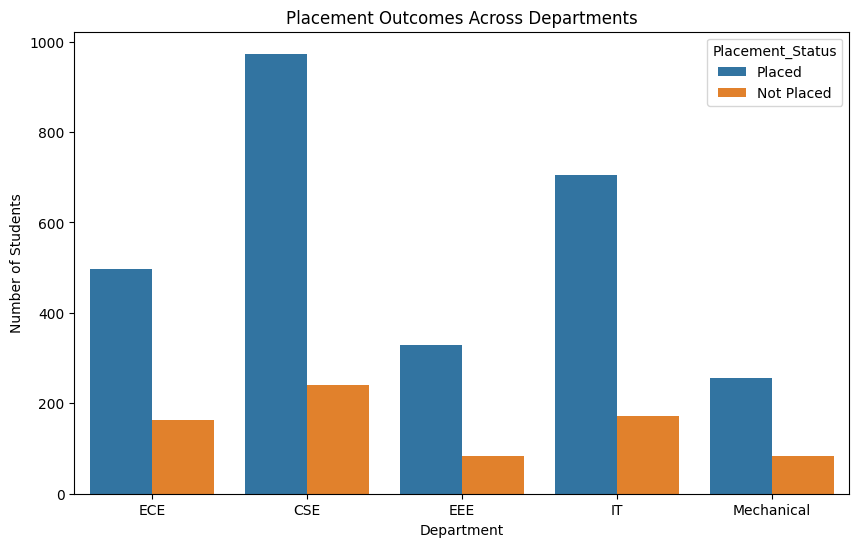

In [22]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x='Department',
    hue='Placement_Status'
)

plt.title('Placement Outcomes Across Departments')
plt.xlabel('Department')
plt.ylabel('Number of Students')

plt.show()

In [23]:
multiple_offers = df[df['Offer_Count'] > 1]

no_offers = df[df['Offer_Count'] == 0]

In [24]:
comparison = pd.DataFrame({
    'Multiple Offers': multiple_offers[
        ['Academic_Performance',
         'Coding_Score',
         'Project_Score',
         'Certifications',
         'Internships',
         'Communication_Score']
    ].mean(),

    'No Offers': no_offers[
        ['Academic_Performance',
         'Coding_Score',
         'Project_Score',
         'Certifications',
         'Internships',
         'Communication_Score']
    ].mean()
})

comparison

,Multiple Offers,No Offers
Academic_Performance,73.301708,68.857561
Coding_Score,72.812915,61.176590
Project_Score,71.572743,66.237615
Certifications,1.989649,1.416442
Internships,1.359977,0.870620
Communication_Score,70.828033,67.931698


In [25]:
certification_analysis = df.groupby('Certifications').agg(
    Students=('Student_ID', 'count'),
    Placement_Rate=('Placement_Status',
                    lambda x: (x == 'Placed').mean() * 100),
    Average_Academic=('Academic_Performance', 'mean')
)

certification_analysis

,Students,Placement_Rate,Average_Academic
Certifications,,,
0.0,576,69.791667,71.923785
1.0,1055,75.924171,71.558076
2.0,942,79.617834,72.798110
3.0,570,85.087719,72.545386
4.0,249,88.353414,72.293976
5.0,77,92.207792,71.507532
6.0,31,93.548387,74.085161


In [26]:
department_analysis = df.groupby('Department').agg(
    Students=('Student_ID', 'count'),
    Placement_Rate=('Placement_Status',
                    lambda x: (x == 'Placed').mean() * 100),
    Average_Coding=('Coding_Score', 'mean'),
    Average_Project=('Project_Score', 'mean'),
    Average_Salary=('Salary', 'mean')
)

department_analysis

,Students,Placement_Rate,Average_Coding,Average_Project,Average_Salary
Department,,,,,
CSE,1214,80.148270,68.583723,69.852776,5.895231
ECE,660,75.151515,68.566500,70.961758,5.686545
EEE,412,79.854369,67.974466,69.887282,5.836796
IT,875,80.457143,68.763771,70.068629,6.025691
Mechanical,339,75.516224,67.693127,70.566401,5.486726


In [28]:
df_ml = pd.get_dummies(
    df,
    columns=['Department', 'Skill_Profile'],
    drop_first=True
)

In [29]:
X = df_ml.drop(
    columns=['Student_ID', 'Placement_Status', 'Offer_Count', 'Salary']
)

y = df_ml['Placement_Status']

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [31]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [32]:
y_pred = rf_model.predict(X_test)

In [33]:
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:",
      round(accuracy * 100, 2), "%")

Random Forest Accuracy: 80.29 %


In [34]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Not Placed       0.60      0.20      0.30       148
      Placed       0.82      0.97      0.89       552

    accuracy                           0.80       700
   macro avg       0.71      0.58      0.59       700
weighted avg       0.77      0.80      0.76       700



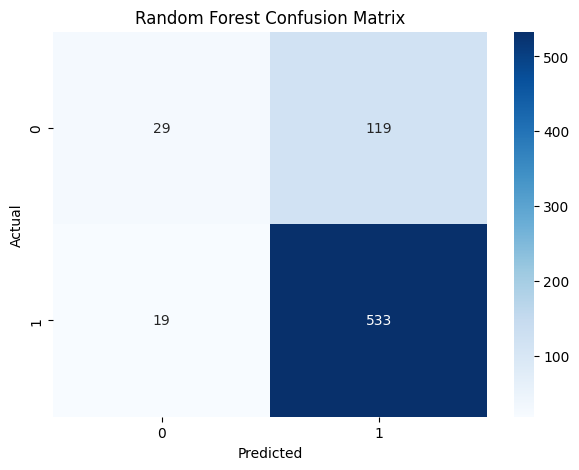

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [36]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
1,Coding_Score,0.208642
0,Academic_Performance,0.180210
2,Project_Score,0.176931
5,Communication_Score,0.173562
3,Certifications,0.064919
4,Internships,0.057729
8,Department_IT,0.018951
6,Department_ECE,0.018452
13,Skill_Profile_Software Development,0.017569
14,Skill_Profile_Web Development,0.017335


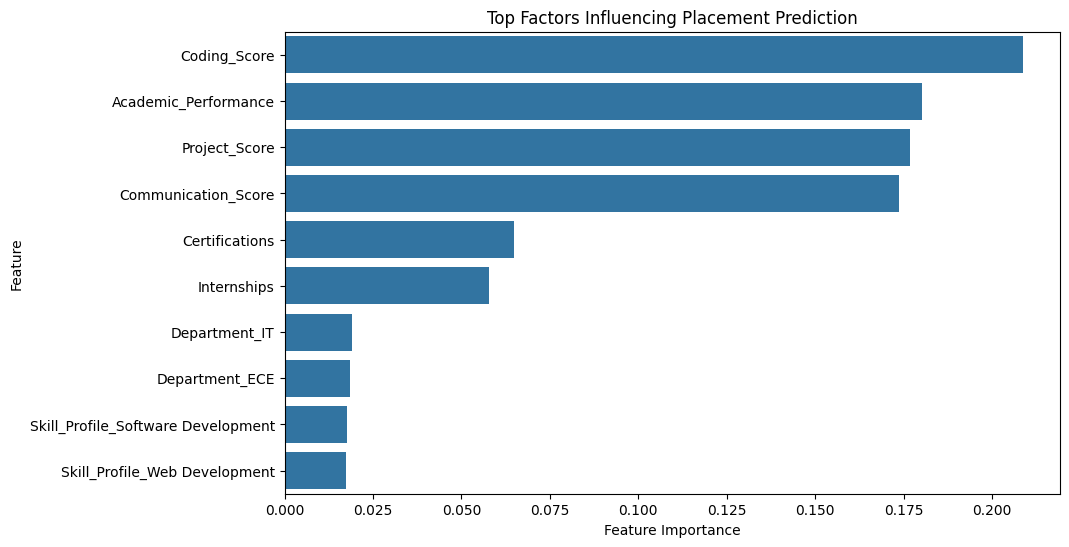

In [37]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top Factors Influencing Placement Prediction')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.show()